In [1]:
REPO = "/kaggle/working/ComputerVisionAndImageProcessing"
!git clone -q https://github.com/nataliachoszczyk/ComputerVisionAndImageProcessing.git {REPO} 2>/dev/null || git -C {REPO} pull
%cd {REPO}/01-image-modification

In [2]:
from pathlib import Path

if not Path("/tmp/div2k").exists():
    !wget -q --show-progress -P /tmp http://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_train_HR.zip
    !wget -q --show-progress -P /tmp http://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_valid_HR.zip
    !unzip -q /tmp/DIV2K_train_HR.zip -d /tmp/div2k
    !unzip -q /tmp/DIV2K_valid_HR.zip -d /tmp/div2k
    !rm /tmp/DIV2K_*.zip

print(len(list(Path("/tmp/div2k").rglob("*.png"))))

DIV2K_train_HR.zip  100%[===================>]   3.29G  30.9MB/s    in 1m 55s  
DIV2K_valid_HR.zip  100%[===================>] 428.19M  26.5MB/s    in 16s     
900


In [3]:
from data import cut_patches
from denoise_data_preparation import SIGMAS, make_noisy_patches

PATCHES = "/tmp/patches"

if not Path(PATCHES).exists():
    cut_patches("/tmp/div2k", PATCHES)
    make_noisy_patches(PATCHES)

train:   0%|          | 0/750 [00:00<?, ?it/s]

val:   0%|          | 0/50 [00:00<?, ?it/s]

test:   0%|          | 0/100 [00:00<?, ?it/s]

train/noise_0.01:   0%|          | 0/30000 [00:00<?, ?it/s]

val/noise_0.01:   0%|          | 0/1757 [00:00<?, ?it/s]

test/noise_0.01:   0%|          | 0/3598 [00:00<?, ?it/s]

train/noise_0.03:   0%|          | 0/30000 [00:00<?, ?it/s]

val/noise_0.03:   0%|          | 0/1757 [00:00<?, ?it/s]

test/noise_0.03:   0%|          | 0/3598 [00:00<?, ?it/s]

In [4]:
for split in ["train", "val", "test"]:
    print(split, {d.name: len(list(d.glob("*.png"))) for d in sorted(Path(PATCHES, split).iterdir())})

train {'noise_0.01': 30000, 'noise_0.03': 30000, 'original': 30000}
val {'noise_0.01': 1757, 'noise_0.03': 1757, 'original': 1757}
test {'noise_0.01': 3598, 'noise_0.03': 3598, 'original': 3598}


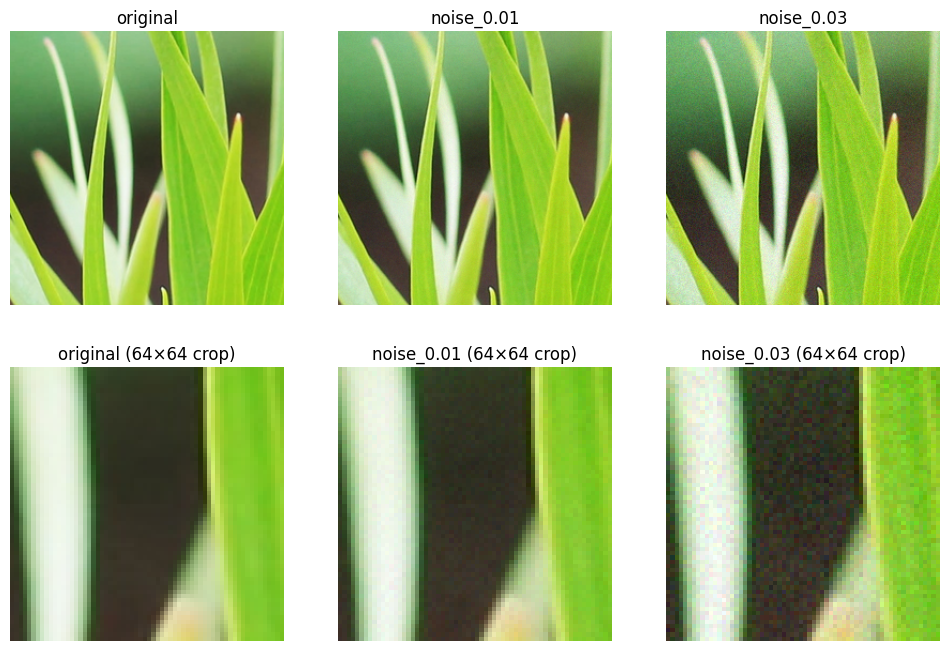

In [5]:
import cv2
import matplotlib.pyplot as plt

name = sorted(Path(PATCHES, "test/original").glob("*.png"))[80].name
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for col, folder in zip(axes.T, ["original"] + [f"noise_{s}" for s in SIGMAS]):
    img = cv2.cvtColor(cv2.imread(f"{PATCHES}/test/{folder}/{name}"), cv2.COLOR_BGR2RGB)
    col[0].imshow(img)
    col[0].set_title(folder)
    col[1].imshow(img[96:160, 96:160], interpolation="nearest")
    col[1].set_title(f"{folder} (64×64 crop)")
for ax in axes.flat:
    ax.axis("off")

In [6]:
!pip install -q lpips

In [7]:
import shutil
from functools import partial

import numpy as np
import pandas as pd
import torch
from joblib import Parallel, delayed
from skimage.restoration import denoise_bilateral

from data import PatchDataset
from metrics import evaluate

WORK = Path("/kaggle/working")
device = "cuda" if torch.cuda.is_available() else "cpu"

for f in Path("/kaggle/input").rglob("*"):
    if f.name.startswith(("unet_sigma", "history_sigma", "bilateral_", "noisy_sigma")):
        shutil.copy(f, WORK)


def bilateral(noisy, sigma_color, sigma_spatial):
    imgs = noisy.cpu().permute(0, 2, 3, 1).numpy()
    out = Parallel(n_jobs=-1)(
        delayed(denoise_bilateral)(img, sigma_color=sigma_color, sigma_spatial=sigma_spatial, channel_axis=2)
        for img in imgs
    )
    return torch.from_numpy(np.stack(out)).permute(0, 3, 1, 2).float()

In [8]:
# default sigma_color (std of the whole image) blurs everything away,
# so pick sigma_color / sigma_spatial on every 8th validation patch
grid_csv = WORK / "bilateral_grid.csv"
if not grid_csv.exists():
    rows = []
    for sigma in SIGMAS:
        val = PatchDataset(f"{PATCHES}/val/noise_{sigma}", f"{PATCHES}/val/original")
        val.input_paths = val.input_paths[::8]
        for k in [0.25, 0.5, 1.0]:
            for sigma_spatial in [1, 2, 3]:
                predict = partial(bilateral, sigma_color=k * sigma, sigma_spatial=sigma_spatial)
                scores = evaluate(predict, val, device, batch_size=64).mean()
                rows.append({"sigma": sigma, "sigma_color": k * sigma, "sigma_spatial": sigma_spatial, **scores})
    pd.DataFrame(rows).to_csv(grid_csv, index=False)

grid = pd.read_csv(grid_csv)
best = grid.loc[grid.groupby("sigma").PSNR.idxmax()].set_index("sigma")
best

  0%|          | 0/4 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth



  0%|          | 0.00/233M [00:00<?, ?B/s]
  4%|▍         | 9.00M/233M [00:00<00:02, 94.2MB/s]
 13%|█▎        | 29.6M/233M [00:00<00:01, 166MB/s] 
 22%|██▏       | 50.2M/233M [00:00<00:01, 189MB/s]
 30%|███       | 70.2M/233M [00:00<00:00, 197MB/s]
 39%|███▉      | 90.4M/233M [00:00<00:00, 202MB/s]
 49%|████▊     | 114M/233M [00:00<00:00, 215MB/s] 
 58%|█████▊    | 134M/233M [00:00<00:00, 204MB/s]
 67%|██████▋   | 157M/233M [00:00<00:00, 215MB/s]
 76%|███████▋  | 178M/233M [00:00<00:00, 208MB/s]
 87%|████████▋ | 202M/233M [00:01<00:00, 222MB/s]
100%|██████████| 233M/233M [00:01<00:00, 210MB/s]


  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

... (12 outputs left out)

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

,sigma_color,sigma_spatial,PSNR,SSIM,LPIPS,SNE
sigma,,,,,,
0.01,0.005,3,42.024637,0.978666,0.016964,13.830697
0.03,0.015,3,34.982496,0.905013,0.078058,70.774895


In [9]:
results = {}
for sigma in SIGMAS:
    test = PatchDataset(f"{PATCHES}/test/noise_{sigma}", f"{PATCHES}/test/original")
    params = best.loc[sigma]
    baselines = {
        "noisy": lambda x: x,
        "bilateral": partial(bilateral, sigma_color=params.sigma_color, sigma_spatial=params.sigma_spatial),
    }
    for name, predict in baselines.items():
        csv = WORK / f"{name}_sigma_{sigma}.csv"
        if not csv.exists():
            evaluate(predict, test, device, batch_size=64).to_csv(csv)
        results[f"{name}_sigma_{sigma}"] = pd.read_csv(csv, index_col=0)

pd.DataFrame({name: df.mean() for name, df in results.items()}).T

  0%|          | 0/57 [00:00<?, ?it/s]

  0%|          | 0/57 [00:00<?, ?it/s]

  0%|          | 0/57 [00:00<?, ?it/s]

  0%|          | 0/57 [00:00<?, ?it/s]

,PSNR,SSIM,LPIPS,SNE
noisy_sigma_0.01,40.038011,0.955183,0.020457,19.523464
bilateral_sigma_0.01,41.901682,0.979033,0.014386,14.032381
noisy_sigma_0.03,30.629528,0.749216,0.145658,170.578502
bilateral_sigma_0.03,34.811161,0.905601,0.069837,71.804921


In [10]:
from model import UNet

model = UNet()
x = torch.rand(2, 3, 256, 256)
print(model(x).shape)
print(sum(p.numel() for p in model.parameters()))

torch.Size([2, 3, 256, 256])
1925667


In [11]:
from training import train

for sigma in SIGMAS:
    if (WORK / f"unet_sigma_{sigma}.pt").exists():
        continue
    train_set = PatchDataset(f"{PATCHES}/train/noise_{sigma}", f"{PATCHES}/train/original")
    val_set = PatchDataset(f"{PATCHES}/val/noise_{sigma}", f"{PATCHES}/val/original")
    history = train(UNet(), train_set, val_set, WORK / f"unet_sigma_{sigma}.pt", epochs=25)
    history.to_csv(WORK / f"history_sigma_{sigma}.csv", index=False)

epoch 1:   0%|          | 0/1875 [00:00<?, ?it/s]

epoch   1 | loss 0.0067 | val PSNR 43.81 dB | 260s


epoch 2:   0%|          | 0/1875 [00:00<?, ?it/s]

epoch   2 | loss 0.0051 | val PSNR 44.16 dB | 268s


epoch 3:   0%|          | 0/1875 [00:00<?, ?it/s]

epoch   3 | loss 0.0049 | val PSNR 44.32 dB | 271s


... (90 outputs left out)

epoch 24:   0%|          | 0/1875 [00:00<?, ?it/s]

epoch  24 | loss 0.0094 | val PSNR 38.86 dB | 277s


epoch 25:   0%|          | 0/1875 [00:00<?, ?it/s]

epoch  25 | loss 0.0093 | val PSNR 38.87 dB | 277s


In [12]:
for sigma in SIGMAS:
    model = UNet()
    model.load_state_dict(torch.load(WORK / f"unet_sigma_{sigma}.pt", map_location=device))
    model.to(device).eval()
    test = PatchDataset(f"{PATCHES}/test/noise_{sigma}", f"{PATCHES}/test/original")
    results[f"unet_sigma_{sigma}"] = evaluate(model, test, device)

table = pd.DataFrame({name: df.mean() for name, df in results.items()}).T
table = table.loc[[f"{m}_sigma_{s}" for s in SIGMAS for m in ["noisy", "bilateral", "unet"]]]
table.to_csv(WORK / "results.csv")
table.round(4)

  0%|          | 0/225 [00:00<?, ?it/s]

  0%|          | 0/225 [00:00<?, ?it/s]

,PSNR,SSIM,LPIPS,SNE
noisy_sigma_0.01,40.0380,0.9552,0.0205,19.5235
bilateral_sigma_0.01,41.9017,0.9790,0.0144,14.0324
unet_sigma_0.01,44.9799,0.9890,0.0068,7.0025
noisy_sigma_0.03,30.6295,0.7492,0.1457,170.5785
bilateral_sigma_0.03,34.8112,0.9056,0.0698,71.8049
unet_sigma_0.03,38.8998,0.9634,0.0356,31.7071


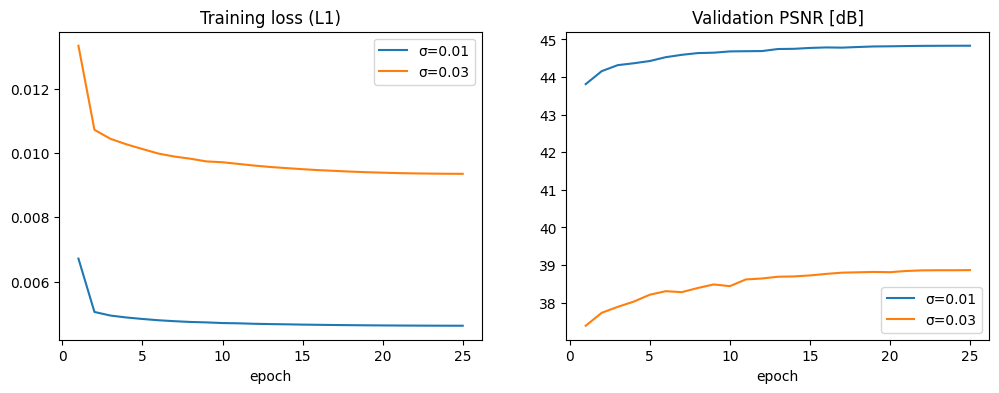

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for sigma in SIGMAS:
    h = pd.read_csv(WORK / f"history_sigma_{sigma}.csv")
    axes[0].plot(h.epoch, h.train_loss, label=f"σ={sigma}")
    axes[1].plot(h.epoch, h.val_psnr, label=f"σ={sigma}")
axes[0].set(title="Training loss (L1)", xlabel="epoch")
axes[1].set(title="Validation PSNR [dB]", xlabel="epoch")
for ax in axes:
    ax.legend()
fig.savefig(WORK / "learning_curves.png", dpi=150, bbox_inches="tight")

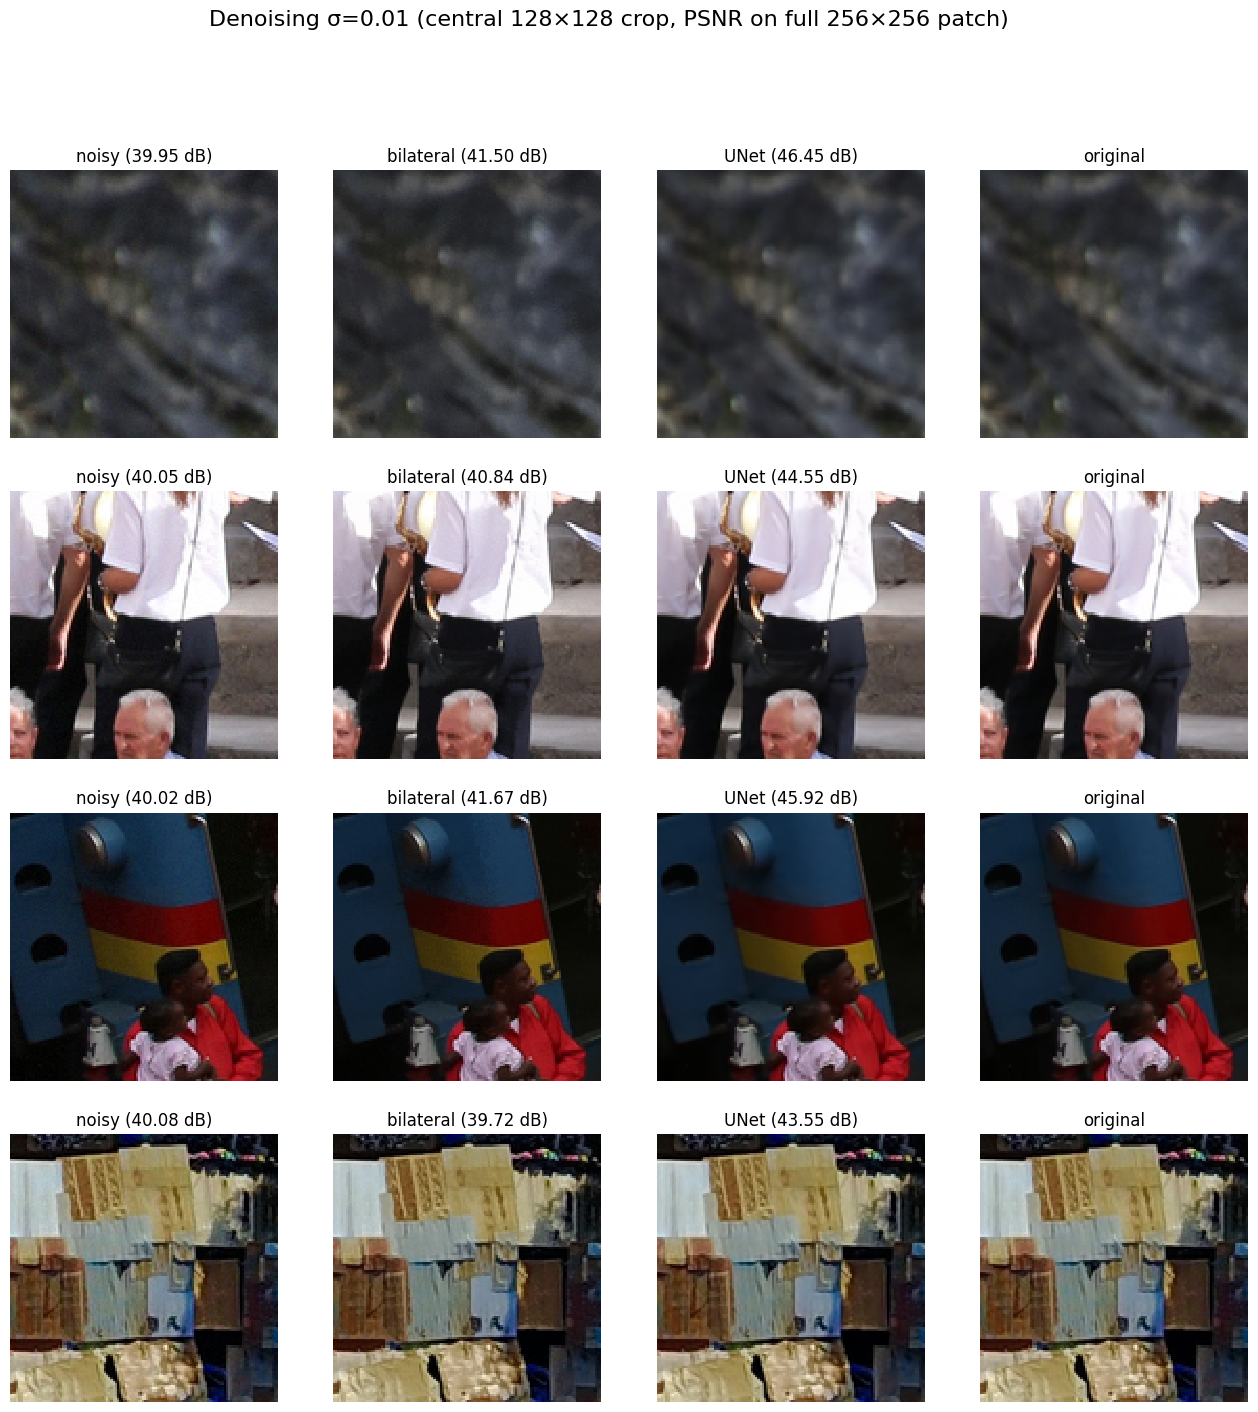

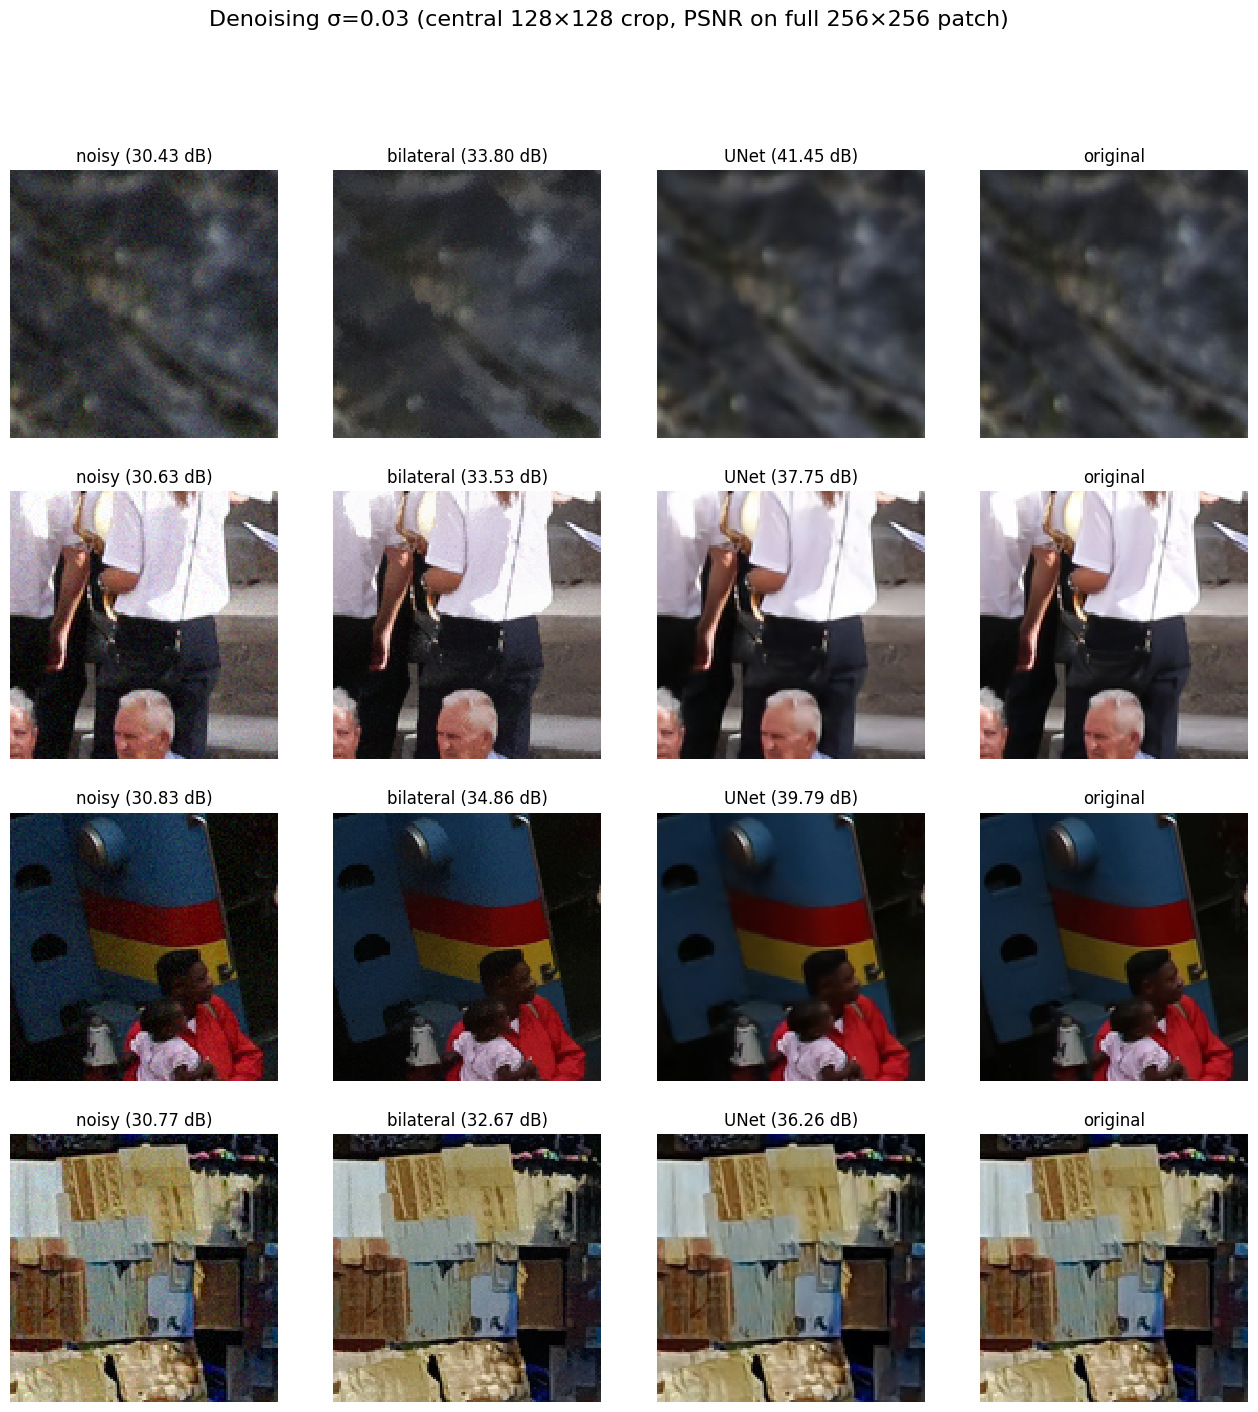

In [14]:
from data import load_image
from metrics import psnr

names = sorted(p.name for p in Path(PATCHES, "test/original").glob("*.png"))[::900]
crop = slice(64, 192)

for sigma in SIGMAS:
    model = UNet()
    model.load_state_dict(torch.load(WORK / f"unet_sigma_{sigma}.pt", map_location="cpu"))
    model.eval()
    params = best.loc[sigma]

    fig, axes = plt.subplots(len(names), 4, figsize=(16, 4 * len(names)))
    for row, name in zip(axes, names):
        noisy = load_image(f"{PATCHES}/test/noise_{sigma}/{name}")[None]
        clean = load_image(f"{PATCHES}/test/original/{name}")[None]
        with torch.no_grad():
            images = {
                "noisy": noisy,
                "bilateral": bilateral(noisy, params.sigma_color, params.sigma_spatial).clamp(0, 1),
                "UNet": model(noisy).clamp(0, 1),
                "original": clean,
            }
        for ax, (title, img) in zip(row, images.items()):
            if title != "original":
                title += f" ({psnr(img, clean).item():.2f} dB)"
            ax.imshow(img[0, :, crop, crop].permute(1, 2, 0).numpy(), interpolation="nearest")
            ax.set_title(title)
            ax.axis("off")
    fig.suptitle(f"Denoising σ={sigma} (central 128×128 crop, PSNR on full 256×256 patch)", fontsize=16)
    fig.savefig(WORK / f"comparison_sigma_{sigma}.png", dpi=100, bbox_inches="tight")